# Constraint Satisfaction Problem : Graph coloring


## Create Data

We can create a planar graph with $n$ vertices by randomly placing $n$ points in 2-dimensional Euclidean space and then performing a [Delaunay triangulation](https://en.wikipedia.org/wiki/Delaunay_triangulation).

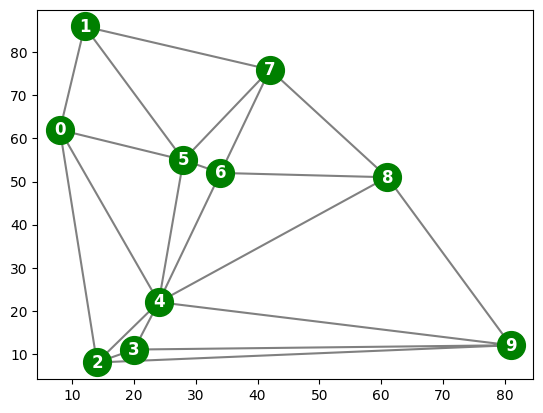

In [14]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.spatial import Delaunay

np.random.seed(1111)

# create points and sort them by
n = 10
points = np.random.randint(100, size=(n, 2))
o = np.argsort(points[:,0])
points = points[o,:]


# triangulate
tri = Delaunay(points)


# plot
plt.triplot(points[:,0], points[:,1], tri.simplices, color = "gray")
plt.plot(points[:,0], points[:,1], 'o', color = "green", markersize = 20)

for i in range(len(points)):
       plt.annotate(i, points[i,:],
        color='white', fontsize="large", weight='heavy',
        horizontalalignment='center', verticalalignment='center')

plt.show()

The triangulation can be converted into a list with an array of neighbor vertex indices for each point (see man page for [scipy.spatial.Delaunay](https://docs.scipy.org/doc/scipy/reference/generated/scipy.spatial.Delaunay.html)).

In [15]:
(indptr, indices) = tri.vertex_neighbor_vertices

neighbors = []

for k in range(len(indptr)-1):
    neighbors.append(np.sort(indices[indptr[k]:indptr[k+1]]))

neighbors

[array([1, 2, 4, 5], dtype=int32),
 array([0, 5, 7], dtype=int32),
 array([0, 3, 4, 9], dtype=int32),
 array([2, 4, 9], dtype=int32),
 array([0, 2, 3, 5, 6, 8, 9], dtype=int32),
 array([0, 1, 4, 6, 7], dtype=int32),
 array([4, 5, 7, 8], dtype=int32),
 array([1, 5, 6, 8], dtype=int32),
 array([4, 6, 7, 9], dtype=int32),
 array([2, 3, 4, 8], dtype=int32)]

The first row are the indices for the points neighboring point 0.

## Define CSP

The problem is defined as a dictionary with variable names, a dictionary with domain values for each variable and a set of binary  not-equal constraints (tuples of variables that are not allowed to have the same value).  

In [16]:
variables = [str(var) for var in range(n)]

domain = ['red', 'blue', 'green', 'orange']
#domain = ['red', 'blue', 'green']
domains = {}
for v in variables:
    domains[v] = domain

# create binary constraints
constraints = {}
for i in range(len(neighbors)):
    for j in neighbors[i]:
        if(i<j): constraints[tuple([str(i), str(j)])] = True
constraints = constraints.keys()

csp = {'variables': variables, 'domains': domains, 'constraints': constraints, }
csp

{'variables': ['0', '1', '2', '3', '4', '5', '6', '7', '8', '9'],
 'domains': {'0': ['red', 'blue', 'green', 'orange'],
  '1': ['red', 'blue', 'green', 'orange'],
  '2': ['red', 'blue', 'green', 'orange'],
  '3': ['red', 'blue', 'green', 'orange'],
  '4': ['red', 'blue', 'green', 'orange'],
  '5': ['red', 'blue', 'green', 'orange'],
  '6': ['red', 'blue', 'green', 'orange'],
  '7': ['red', 'blue', 'green', 'orange'],
  '8': ['red', 'blue', 'green', 'orange'],
  '9': ['red', 'blue', 'green', 'orange']},
 'constraints': dict_keys([('0', '1'), ('0', '2'), ('0', '4'), ('0', '5'), ('1', '5'), ('1', '7'), ('2', '3'), ('2', '4'), ('2', '9'), ('3', '4'), ('3', '9'), ('4', '5'), ('4', '6'), ('4', '8'), ('4', '9'), ('5', '6'), ('5', '7'), ('6', '7'), ('6', '8'), ('7', '8'), ('8', '9')])}

## Check Completeness and Consistency

`assignment` is a dictionary. Assigned variables have an entry with the variable name as the key. `{}` is therefore the empty assignment.

In [17]:
def complete(assignment, csp):
    return(all([v in assignment.keys() for v in csp['variables']]))

print("complete({}, csp) =", complete({}, csp))

print("complete({...complete list...}, csp) =",
      complete({'0': 'red', '1': 'red', '2': 'red', '3': 'red', '4': 'red',
          '5': 'red', '6': 'red', '7': 'red', '8': 'red', '9': 'red'}, csp))

complete({}, csp) = False
complete({...complete list...}, csp) = True


In [18]:
def consistent(assignment, csp):
    for constr in csp['constraints']:
        if(constr[0] in assignment.keys() and constr[1] in assignment.keys()):
            if assignment[constr[0]] == assignment[constr[1]]: return(False)

    return(True)

print("consistent({}, csp) =", consistent({}, csp))
print("consistent({'0': 'red', '1': 'red', '2': 'blue'}, csp) =",
      consistent({'0': 'red', '1': 'red', '2': 'blue'}, csp))

consistent({}, csp) = True
consistent({'0': 'red', '1': 'red', '2': 'blue'}, csp) = False


## Implement Simple Backtracking Search

In [19]:
def select_unassigned_var(assignment, csp):
    """Chiến lược MRV: Chọn biến chưa gán có số lượng giá trị hợp lệ còn lại ít nhất."""
    if complete(assignment, csp):
        return None

    unassigned_vars = [v for v in csp['variables'] if v not in assignment.keys()]

    def count_valid_values(var):
        valid_count = 0
        for val in csp['domains'][var]:
            assignment[var] = val
            if consistent(assignment, csp):
                valid_count += 1
            del assignment[var]
        return valid_count

    return min(unassigned_vars, key=count_valid_values)

print("select_unassigned_var({'0': 'red', '1': 'blue'}, csp) =",
     select_unassigned_var({'0': 'red', '1': 'blue'}, csp))

select_unassigned_var({'0': 'red', '1': 'blue'}, csp) = 5


In [20]:
# I use a global variable to turn on verbose mode in the recursion
#VERBOSE = True
VERBOSE = False
COUNT = 0

def order_domain_values(assignment, var, csp):
    """Chiến lược LCV: Sắp xếp các giá trị sao cho giá trị nào loại ít lựa chọn của láng giềng nhất được ưu tiên trước."""
    def count_conflicts(val):
        conflict_count = 0
        assignment[var] = val
        for constr in csp['constraints']:
            u, v = constr
            neighbor = None
            if u == var and v not in assignment:
                neighbor = v
            elif v == var and u not in assignment:
                neighbor = u

            if neighbor is not None:
                if val in csp['domains'][neighbor]:
                    conflict_count += 1
        del assignment[var]
        return conflict_count

    return sorted(csp['domains'][var], key=count_conflicts)

# returns None for failure
def backtrack_search(csp):
    global COUNT
    COUNT = 0

    assignment = backtrack({}, csp)

    print(f"Checked nodes: {COUNT}")

    return assignment

def backtrack(assignment, csp):
    global VERBOSE, COUNT

    COUNT += 1

    if complete(assignment, csp):
        return assignment

    var = select_unassigned_var(assignment, csp)
    if var is None:
        return None

    # Duyệt các giá trị theo thứ tự tối ưu LCV
    for val in order_domain_values(assignment, var, csp):
        assignment[var] = val

        if VERBOSE: print(f"Checking: {assignment}")

        if consistent(assignment, csp):
            result = backtrack(assignment, csp)
            if not result is None:
                    return(result)

        del assignment[var]

    if VERBOSE: print(f"Backtracking")
    return(None)

## Run Backtracking Search on the Random Problem

In [21]:
%time res = backtrack_search(csp)
display(res)

Checked nodes: 11
CPU times: total: 0 ns
Wall time: 697 μs


{'0': 'red',
 '1': 'blue',
 '5': 'green',
 '4': 'blue',
 '2': 'green',
 '3': 'red',
 '9': 'orange',
 '6': 'red',
 '7': 'orange',
 '8': 'green'}

Plot the resulting coloring

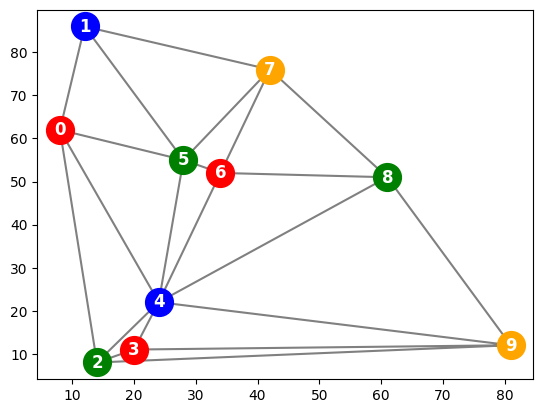

In [22]:
plt.triplot(points[:, 0], points[:, 1], tri.simplices, color="gray")

for i in range(len(points)):
  node_color = res[str(i)] if str(i) in res else res[i]

  plt.plot(
      points[i, 0], points[i, 1], "o", color=node_color, markersize=20
  )
  plt.annotate(
      str(i),
      points[i, :],
      color="white",
      fontsize="large",
      weight="heavy",
      horizontalalignment="center",
      verticalalignment="center",
  )

plt.show()

## Assignment

Implement the following graph coloring algorithms:

* Add variable and value ordering to the implementation.
* Add forward checking to the implementation.
* Implement hill climbing local search with the min-conflicts heuristic.

Try to color graphs of several sizes with 3 and 4 colors. For each $n$, generate several random instances, and try to make n as large as you can manage. On average, how many constraints (edges) do your map coloring instances have for each $n$? Report the performance of each search algorithm as a function of $n$. For both variants of backtracking search, you can characterize performance in terms of the number of variable assignments attempted. For hill climbing search, report the number of uphill moves and random restarts required in order to reach a solution. Of course, you can also report raw running times as a function of $n$.

## 1. Forward Checking

Forward Checking cải tiến thuật toán Backtracking bằng cách cập nhật miền giá trị của các biến chưa được gán sau mỗi lần gán màu cho một đỉnh. Những màu trùng với màu của đỉnh vừa gán sẽ bị loại khỏi miền của các đỉnh láng giềng.

Nếu miền của một đỉnh trở thành rỗng, thuật toán phát hiện nhánh thất bại sớm và quay lui. Khi quay lui, các miền giá trị phải được khôi phục để không ảnh hưởng đến những nhánh tìm kiếm khác.

Trong phần này, Forward Checking kết hợp MRV để chọn biến và LCV để sắp xếp giá trị. Số lần thử gán biến và thời gian chạy được ghi nhận để đánh giá hiệu quả.

In [23]:
import time
import copy

def forward_checking_search(csp):
    start_time = time.perf_counter()

    variables = csp['variables']
    constraints = list(csp['constraints'])

    # Tạo danh sách láng giềng từ các ràng buộc hiện có.
    adjacency = {v: [] for v in variables}

    for u, v in constraints:
        adjacency[u].append(v)
        adjacency[v].append(u)

    # Sao chép miền để không thay đổi dữ liệu CSP ban đầu.
    initial_domains = {
        v: list(csp['domains'][v]) for v in variables
    }

    assignment = {}
    count = 0

    def select_mrv(current_domains):
        unassigned = [
            v for v in variables if v not in assignment
        ]

        if not unassigned:
            return None

        return min(
            unassigned,
            key=lambda v: len(current_domains[v])
        )

    def order_lcv(var, current_domains):
        def count_removed_values(color):
            removed = 0

            for neighbor in adjacency[var]:
                if neighbor not in assignment:
                    if color in current_domains[neighbor]:
                        removed += 1

            return removed

        return sorted(
            current_domains[var],
            key=count_removed_values
        )

    def backtrack(current_domains):
        nonlocal count

        if len(assignment) == len(variables):
            return assignment.copy()

        var = select_mrv(current_domains)

        if var is None or len(current_domains[var]) == 0:
            return None

        for color in order_lcv(var, current_domains):
            count += 1

            # Chỉ thử màu không vi phạm các đỉnh đã gán.
            valid = all(
                assignment.get(neighbor) != color
                for neighbor in adjacency[var]
            )

            if not valid:
                continue

            assignment[var] = color

            # Lưu miền trước khi loại các màu xung đột.
            new_domains = copy.deepcopy(current_domains)
            failed = False

            for neighbor in adjacency[var]:
                if neighbor not in assignment:
                    if color in new_domains[neighbor]:
                        new_domains[neighbor].remove(color)

                    # Miền rỗng: phát hiện thất bại sớm.
                    if len(new_domains[neighbor]) == 0:
                        failed = True
                        break

            if not failed:
                result = backtrack(new_domains)

                if result is not None:
                    return result

            # Quay lui: bỏ phép gán hiện tại.
            # Miền được khôi phục nhờ bản sao new_domains
            # cục bộ của từng nhánh.
            del assignment[var]

        return None

    solution = backtrack(initial_domains)
    elapsed = time.perf_counter() - start_time

    return {
        'solution': solution,
        'count': count,
        'time': elapsed,
        'success': solution is not None
    }


# Chạy thử trên CSP đã tạo ở các cell trước.
fc_result = forward_checking_search(csp)

print("Forward Checking")
print("Tìm thấy nghiệm:", fc_result['success'])
print("Số lần thử gán:", fc_result['count'])
print("Thời gian (giây):", round(fc_result['time'], 6))
print("Phép gán:", fc_result['solution'])

Forward Checking
Tìm thấy nghiệm: True
Số lần thử gán: 10
Thời gian (giây): 0.000215
Phép gán: {'0': 'red', '1': 'blue', '5': 'green', '4': 'blue', '2': 'green', '3': 'red', '9': 'orange', '6': 'orange', '7': 'red', '8': 'green'}


## 2. Min-Conflicts

Min-Conflicts là thuật toán tìm kiếm cục bộ dành cho bài toán CSP. Khác với Backtracking, thuật toán khởi tạo một phép gán đầy đủ, dù phép gán ban đầu có thể vi phạm các ràng buộc.

Ở mỗi bước, thuật toán chọn ngẫu nhiên một biến đang vi phạm ràng buộc và thay đổi giá trị của biến đó bằng giá trị làm giảm số xung đột nhiều nhất. Nếu có nhiều giá trị cùng tốt nhất, thuật toán chọn ngẫu nhiên để tăng tính đa dạng của tìm kiếm.

Thuật toán dừng khi tìm được phép gán hợp lệ hoặc đạt giới hạn số bước và số lần khởi động lại. Vì đây là tìm kiếm cục bộ, việc không tìm thấy nghiệm trong giới hạn cho phép không chứng minh rằng CSP vô nghiệm.

In [24]:
import random
import time

def min_conflicts_search(
    csp,
    max_steps=5000,
    max_restarts=10,
    seed=1234
):
    rng = random.Random(seed)
    start_time = time.perf_counter()

    variables = csp['variables']
    domains = csp['domains']
    constraints = list(csp['constraints'])

    adjacency = {v: [] for v in variables}

    for u, v in constraints:
        adjacency[u].append(v)
        adjacency[v].append(u)

    total_steps = 0
    restarts_used = 0
    solution = None

    def conflicted_variables(assignment):
        return [
            v for v in variables
            if any(
                assignment[v] == assignment[neighbor]
                for neighbor in adjacency[v]
            )
        ]

    def value_conflicts(var, color, assignment):
        return sum(
            assignment[neighbor] == color
            for neighbor in adjacency[var]
        )

    # max_restarts là số lần khởi động lại thêm,
    # ngoài lần khởi tạo đầu tiên.
    for restart in range(max_restarts + 1):
        assignment = {
            v: rng.choice(domains[v]) for v in variables
        }

        for step in range(max_steps + 1):
            conflicted = conflicted_variables(assignment)

            if not conflicted:
                solution = assignment.copy()
                break

            if step == max_steps:
                break

            # Chọn ngẫu nhiên một biến đang vi phạm.
            var = rng.choice(conflicted)

            # Chọn màu có số xung đột nhỏ nhất.
            scores = {
                color: value_conflicts(var, color, assignment)
                for color in domains[var]
            }

            best_score = min(scores.values())

            best_colors = [
                color for color, score in scores.items()
                if score == best_score
            ]

            new_color = rng.choice(best_colors)

            assignment[var] = new_color
            total_steps += 1

        if solution is not None:
            restarts_used = restart
            break

        restarts_used = restart

    elapsed = time.perf_counter() - start_time

    return {
        'solution': solution,
        'success': solution is not None,
        'steps': total_steps,
        'restarts': restarts_used,
        'time': elapsed
    }


# Chạy thử trên CSP đã tạo ở các cell trước.
mc_result = min_conflicts_search(csp, seed=1234)

print("Min-Conflicts")
print("Tìm thấy nghiệm:", mc_result['success'])
print("Số bước thay đổi màu:", mc_result['steps'])
print("Số lần khởi động lại:", mc_result['restarts'])
print("Thời gian (giây):", round(mc_result['time'], 6))
print("Phép gán:", mc_result['solution'])

Min-Conflicts
Tìm thấy nghiệm: True
Số bước thay đổi màu: 20
Số lần khởi động lại: 0
Thời gian (giây): 0.000207
Phép gán: {'0': 'orange', '1': 'blue', '2': 'red', '3': 'blue', '4': 'green', '5': 'red', '6': 'orange', '7': 'green', '8': 'blue', '9': 'orange'}


In [25]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import time

def generate_random_csp(n, num_colors, seed):
    rng = np.random.default_rng(seed)

    # Sinh tọa độ thực để hạn chế các điểm trùng nhau.
    points_exp = rng.random((n, 2)) * 100
    tri_exp = Delaunay(points_exp)

    edges = set()

    for simplex in tri_exp.simplices:
        for i in range(len(simplex)):
            for j in range(i + 1, len(simplex)):
                u = int(simplex[i])
                v = int(simplex[j])
                edges.add((min(u, v), max(u, v)))

    variables_exp = [str(i) for i in range(n)]
    colors_exp = ['red', 'blue', 'green', 'orange'][:num_colors]

    domains_exp = {
        v: list(colors_exp) for v in variables_exp
    }

    constraints_exp = [
        (str(u), str(v)) for u, v in sorted(edges)
    ]

    csp_exp = {
        'variables': variables_exp,
        'domains': domains_exp,
        'constraints': constraints_exp
    }

    return points_exp, tri_exp, csp_exp


# Có thể tăng số lần thử sau khi kiểm tra code chạy ổn.
sizes = [10, 15, 20]
color_counts = [3, 4]
trials = 3

experiment_rows = []

for n_exp in sizes:
    for k_colors in color_counts:
        for trial in range(trials):
            seed = 1000 + n_exp * 100 + k_colors * 10 + trial

            points_exp, tri_exp, csp_exp = generate_random_csp(
                n_exp, k_colors, seed
            )

            # Forward Checking
            fc = forward_checking_search(csp_exp)

            # Min-Conflicts trên cùng đồ thị
            mc = min_conflicts_search(
                csp_exp,
                max_steps=5000,
                max_restarts=10,
                seed=seed
            )

            experiment_rows.append({
                'n': n_exp,
                'colors': k_colors,
                'trial': trial + 1,
                'edges': len(csp_exp['constraints']),
                'FC_success': int(fc['success']),
                'FC_count': fc['count'],
                'FC_time': fc['time'],
                'MC_success': int(mc['success']),
                'MC_steps': mc['steps'],
                'MC_restarts': mc['restarts'],
                'MC_time': mc['time']
            })

experiment_df = pd.DataFrame(experiment_rows)

print("Kết quả từng lần thử:")
display(experiment_df.round(4))

# Tổng hợp theo kích thước và số màu.
summary_df = experiment_df.groupby(
    ['n', 'colors'], as_index=False
).agg(
    avg_edges=('edges', 'mean'),
    FC_success_rate=('FC_success', 'mean'),
    FC_avg_count=('FC_count', 'mean'),
    FC_avg_time=('FC_time', 'mean'),
    MC_success_rate=('MC_success', 'mean'),
    MC_avg_steps=('MC_steps', 'mean'),
    MC_avg_restarts=('MC_restarts', 'mean'),
    MC_avg_time=('MC_time', 'mean')
)

summary_df['FC_success_rate'] *= 100
summary_df['MC_success_rate'] *= 100

print("Bảng tổng hợp:")
display(summary_df.round(4))

Kết quả từng lần thử:


,n,colors,trial,edges,FC_success,FC_count,FC_time,MC_success,MC_steps,MC_restarts,MC_time
0,10,3,1,22,0,27,0.0005,0,55000,10,0.3658
1,10,3,2,21,0,15,0.0003,0,55000,10,0.3431
2,10,3,3,21,1,10,0.0002,1,13,0,0.0001
3,10,4,1,22,1,10,0.0002,1,8,0,0.0001
4,10,4,2,21,1,10,0.0002,1,2,0,0.0000
5,10,4,3,21,1,10,0.0002,1,8,0,0.0001
6,15,3,1,34,0,45,0.0008,0,55000,10,0.4737
7,15,3,2,36,0,33,0.0007,0,55000,10,0.4684
8,15,3,3,36,0,33,0.0007,0,55000,10,0.4636
9,15,4,1,35,1,15,0.0004,1,29,0,0.0003


Bảng tổng hợp:


,n,colors,avg_edges,FC_success_rate,FC_avg_count,FC_avg_time,MC_success_rate,MC_avg_steps,MC_avg_restarts,MC_avg_time
0,10,3,21.3333,33.3333,17.3333,0.0003,33.3333,36671.0000,6.6667,0.2363
1,10,4,21.3333,100.0000,10.0000,0.0002,100.0000,6.0000,0.0000,0.0001
2,15,3,35.3333,0.0000,37.0000,0.0007,0.0000,55000.0000,10.0000,0.4686
3,15,4,35.6667,100.0000,18.0000,0.0004,100.0000,38.6667,0.0000,0.0004
4,20,3,49.0000,0.0000,31.0000,0.0008,0.0000,55000.0000,10.0000,0.6251
5,20,4,49.0000,100.0000,20.0000,0.0006,100.0000,32.3333,0.0000,0.0004


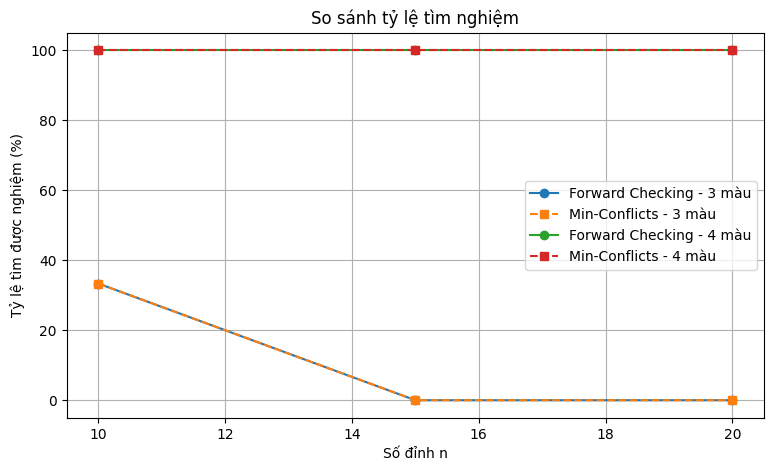

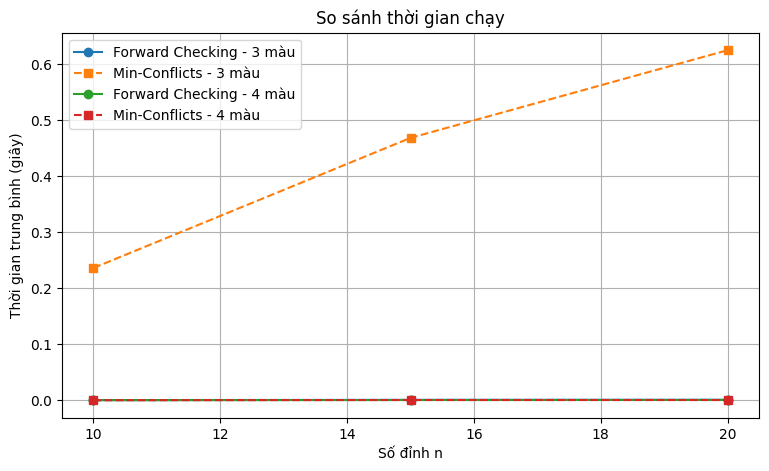

In [26]:
# Biểu đồ 1: Tỷ lệ tìm được nghiệm
plt.figure(figsize=(9, 5))

for k_colors in color_counts:
    subset = summary_df[summary_df['colors'] == k_colors]

    plt.plot(
        subset['n'],
        subset['FC_success_rate'],
        marker='o',
        label=f'Forward Checking - {k_colors} màu'
    )

    plt.plot(
        subset['n'],
        subset['MC_success_rate'],
        marker='s',
        linestyle='--',
        label=f'Min-Conflicts - {k_colors} màu'
    )

plt.xlabel('Số đỉnh n')
plt.ylabel('Tỷ lệ tìm được nghiệm (%)')
plt.title('So sánh tỷ lệ tìm nghiệm')
plt.ylim(-5, 105)
plt.grid(True)
plt.legend()
plt.show()


# Biểu đồ 2: Thời gian chạy trung bình
plt.figure(figsize=(9, 5))

for k_colors in color_counts:
    subset = summary_df[summary_df['colors'] == k_colors]

    plt.plot(
        subset['n'],
        subset['FC_avg_time'],
        marker='o',
        label=f'Forward Checking - {k_colors} màu'
    )

    plt.plot(
        subset['n'],
        subset['MC_avg_time'],
        marker='s',
        linestyle='--',
        label=f'Min-Conflicts - {k_colors} màu'
    )

plt.xlabel('Số đỉnh n')
plt.ylabel('Thời gian trung bình (giây)')
plt.title('So sánh thời gian chạy')
plt.grid(True)
plt.legend()
plt.show()
